In [ ]:
import os
import sys
import shutil
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = "/content/drive/MyDrive/kits19_processed"

Mounted at /content/drive


In [ ]:
manifest = pd.read_csv(os.path.join(DATA_DIR, "manifest.csv"))
merged = pd.read_csv(os.path.join(DATA_DIR, "merged_metadata.csv"))
train_cases = pd.read_csv(os.path.join(DATA_DIR, "train_cases.csv"))["case_id"].tolist()

print("Manifest rows:", len(manifest))
print("Train/val/test counts:", len(train_cases),
      len(pd.read_csv(os.path.join(DATA_DIR, "val_cases.csv"))),
      len(pd.read_csv(os.path.join(DATA_DIR, "test_cases.csv"))))

# Load one real case and check it matches what preprocessing.py produced
sample_id = train_cases[0]
image = np.load(os.path.join(DATA_DIR, sample_id, "image.npy"))
mask = np.load(os.path.join(DATA_DIR, sample_id, "mask.npy"))

print(f"\n{sample_id}")
print("image shape:", image.shape, "dtype:", image.dtype, "range:", image.min(), "to", image.max())
print("mask shape:", mask.shape, "unique labels:", np.unique(mask))
print("tumor voxels:", (mask == 2).sum())

Manifest rows: 210
Train/val/test counts: 146 32 32

case_00073
image shape: (96, 160, 160) dtype: float32 range: -200.0 to 300.0
mask shape: (96, 160, 160) unique labels: [0 1 2]
tumor voxels: 53017


In [ ]:
HU_MIN, HU_MAX = -200.0, 300.0
DEFAULT_PATCH_SIZE = (24, 48, 48)   # shrunk from (32,64,64) — see diagnosis below
TUMOR_CENTER_FRAC = 0.5
MIN_TUMOR_VOXELS_FOR_POSITIVE = 10
MAX_RESAMPLE_ATTEMPTS = 20


def normalize(image):
    return (image - HU_MIN) / (HU_MAX - HU_MIN)


class KidneyPatchDataset(Dataset):
    def __init__(
        self,
        data_dir,
        split_csv,
        patch_size=DEFAULT_PATCH_SIZE,
        patches_per_epoch=2000,
        tumor_center_frac=TUMOR_CENTER_FRAC,
        preload=True,
        seed=None,  # NEW: if set, this dataset is FIXED — same patches every epoch
    ):
        self.data_dir = data_dir
        self.patch_size = patch_size
        self.patches_per_epoch = patches_per_epoch
        self.tumor_center_frac = tumor_center_frac
        self.preload = preload
        self.seed = seed
        self._fallback_count = 0
        self._fallback_by_case = {}

        case_ids = pd.read_csv(os.path.join(data_dir, split_csv))["case_id"].tolist()
        self.case_ids = case_ids

        self._cache = {}
        if preload:
            for case_id in case_ids:
                self._cache[case_id] = self._load_case(case_id)

        self._tumor_coords = {}
        self._kidney_coords = {}
        for case_id in case_ids:
            _, mask = self._get_case(case_id)
            tumor_coords = np.argwhere(mask == 2)
            kidney_coords = np.argwhere(mask == 1)
            self._tumor_coords[case_id] = tumor_coords if len(tumor_coords) > 0 else kidney_coords
            self._kidney_coords[case_id] = kidney_coords if len(kidney_coords) > 0 else tumor_coords

        # If a seed is given, materialize the ENTIRE dataset once, up front,
        # using its own private RNG. This makes it reproducible and fixed
        # across epochs — essential for a real validation/test set.
        self._fixed_items = None
        if self.seed is not None:
            rng = np.random.RandomState(self.seed)
            self._fixed_items = [self._draw_one(rng) for _ in range(self.patches_per_epoch)]

    def _load_case(self, case_id):
        image = np.load(os.path.join(self.data_dir, case_id, "image.npy"))
        mask = np.load(os.path.join(self.data_dir, case_id, "mask.npy"))
        return image, mask

    def _get_case(self, case_id):
        if self.preload:
            return self._cache[case_id]
        return self._load_case(case_id)

    def __len__(self):
        return self.patches_per_epoch

    def _extract_patch(self, image, mask, center):
        pd_, ph, pw = self.patch_size
        shape = image.shape

        def bounds(c, p, dim_size):
            start = int(c - p // 2)
            start = max(0, min(start, dim_size - p))
            return start, start + p

        z0, z1 = bounds(center[0], pd_, shape[0])
        y0, y1 = bounds(center[1], ph, shape[1])
        x0, x1 = bounds(center[2], pw, shape[2])

        image_patch = image[z0:z1, y0:y1, x0:x1]
        mask_patch = mask[z0:z1, y0:y1, x0:x1]
        return image_patch, mask_patch

    def _draw_one(self, rng):
        case_id = self.case_ids[rng.randint(len(self.case_ids))]
        image, mask = self._get_case(case_id)

        want_positive = rng.rand() < self.tumor_center_frac
        coords = self._tumor_coords[case_id] if want_positive else self._kidney_coords[case_id]

        image_patch = mask_patch = None
        label = 0
        matched = False
        for _ in range(MAX_RESAMPLE_ATTEMPTS):
            center = coords[rng.randint(len(coords))]
            candidate_image, candidate_mask = self._extract_patch(image, mask, center)
            tumor_voxel_count = int((candidate_mask == 2).sum())
            candidate_label = 1 if tumor_voxel_count >= MIN_TUMOR_VOXELS_FOR_POSITIVE else 0

            image_patch, mask_patch, label = candidate_image, candidate_mask, candidate_label
            if candidate_label == int(want_positive):
                matched = True
                break

        if not matched:
            self._fallback_count += 1
            self._fallback_by_case[case_id] = self._fallback_by_case.get(case_id, 0) + 1

        image_patch = normalize(image_patch).astype(np.float32)
        image_tensor = torch.from_numpy(image_patch).unsqueeze(0)
        label_tensor = torch.tensor(label, dtype=torch.float32)
        return image_tensor, label_tensor

    def __getitem__(self, idx):
        if self._fixed_items is not None:
            return self._fixed_items[idx]
        return self._draw_one(np.random)


# --- Balance sanity check ---
ds = KidneyPatchDataset(DATA_DIR, "train_cases.csv", patches_per_epoch=500, preload=True)

labels = []
for i in range(len(ds)):
    image_patch, label = ds[i]
    labels.append(int(label.item()))
    if i == 0:
        print("Patch shape:", image_patch.shape, "dtype:", image_patch.dtype)
        print("Patch value range:", image_patch.min().item(), "to", image_patch.max().item())

pos_frac = sum(labels) / len(labels)
fallback_frac = ds._fallback_count / len(ds)
print(f"\nSampled {len(labels)} patches -> positive fraction: {pos_frac:.2f} "
      f"(target ~{TUMOR_CENTER_FRAC:.2f}, will vary run to run)")
print(f"Fallback rate: {fallback_frac:.2%}")

# --- Diagnostic: which cases are driving fallbacks? ---
merged = pd.read_csv(os.path.join(DATA_DIR, "merged_metadata.csv"))
size_lookup = dict(zip(merged["case_id"], merged["tumor_size_group"]))

fallback_groups = [size_lookup.get(cid, "unknown") for cid in ds._fallback_by_case.keys()]
if fallback_groups:
    print("\nFallback cases by tumor_size_group:")
    print(pd.Series(fallback_groups).value_counts())
else:
    print("\nNo fallback cases recorded.")

Patch shape: torch.Size([1, 24, 48, 48]) dtype: torch.float32
Patch value range: 0.0 to 1.0

Sampled 500 patches -> positive fraction: 0.60 (target ~0.50, will vary run to run)
Fallback rate: 9.80%

Fallback cases by tumor_size_group:
Large (>=40 mm)      23
Medium (20-40 mm)     5
Small (<20 mm)        1
Name: count, dtype: int64


In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    n_batches = 0
    all_probs = []
    all_labels = []

    with torch.set_grad_enabled(is_train):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item()
            n_batches += 1

            probs = torch.sigmoid(logits).detach().cpu().numpy()
            all_probs.extend(probs.tolist())
            all_labels.extend(labels.detach().cpu().numpy().tolist())

    preds = [1 if p >= 0.5 else 0 for p in all_probs]
    sensitivity = recall_score(all_labels, preds, zero_division=0)
    precision = precision_score(all_labels, preds, zero_division=0)
    f1 = f1_score(all_labels, preds, zero_division=0)
    try:
        auroc = roc_auc_score(all_labels, all_probs)
    except ValueError:
        auroc = float("nan")

    return {
        "loss": total_loss / n_batches,
        "sensitivity": sensitivity,
        "precision": precision,
        "f1": f1,
        "auroc": auroc,
    }


In [ ]:
class Simple3DCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv3d(1, 16, 3, padding=1), nn.GroupNorm(4, 16), nn.ReLU(), nn.MaxPool3d(2),
            nn.Conv3d(16, 32, 3, padding=1), nn.GroupNorm(8, 32), nn.ReLU(), nn.MaxPool3d(2),
            nn.Conv3d(32, 64, 3, padding=1), nn.GroupNorm(8, 64), nn.ReLU(), nn.MaxPool3d(2),
        )
        self.pool = nn.AdaptiveAvgPool3d(1)
        self.classifier = nn.Linear(64, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        return self.classifier(x).squeeze(1)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Simple3DCNN().to(device)

measured_pos_frac = 0.64
pos_weight = torch.tensor([(1 - measured_pos_frac) / measured_pos_frac]).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)          # lowered from 1e-3
scheduler = ReduceLROnPlateau(optimizer, mode="min", patience=2, factor=0.5)

train_ds = KidneyPatchDataset(DATA_DIR, "train_cases.csv", patches_per_epoch=2000, preload=True)
val_ds   = KidneyPatchDataset(DATA_DIR, "val_cases.csv",   patches_per_epoch=400,  preload=True, seed=42)
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

best_val_auroc = -1.0
best_state = None

NUM_EPOCHS = 20
for epoch in range(1, NUM_EPOCHS + 1):
    train_metrics = run_epoch(model, train_loader, criterion, optimizer)
    val_metrics = run_epoch(model, val_loader, criterion, optimizer=None)
    scheduler.step(val_metrics["loss"])

    if val_metrics["auroc"] > best_val_auroc:
        best_val_auroc = val_metrics["auroc"]
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    current_lr = optimizer.param_groups[0]["lr"]
    print(f"Epoch {epoch:2d} | lr {current_lr:.1e} | "
          f"train loss {train_metrics['loss']:.4f} | "
          f"val loss {val_metrics['loss']:.4f} sens {val_metrics['sensitivity']:.2f} "
          f"prec {val_metrics['precision']:.2f} f1 {val_metrics['f1']:.2f} "
          f"auroc {val_metrics['auroc']:.2f}")

print(f"\nBest val AUROC: {best_val_auroc:.3f}")
torch.save(best_state, "model2_best.pt")

Epoch  1 | lr 5.0e-04 | train loss 0.4975 | val loss 0.5109 sens 0.48 prec 0.63 f1 0.55 auroc 0.55
Epoch  2 | lr 5.0e-04 | train loss 0.4905 | val loss 0.5109 sens 0.06 prec 0.62 f1 0.11 auroc 0.55
Epoch  3 | lr 5.0e-04 | train loss 0.4788 | val loss 0.5228 sens 0.71 prec 0.66 f1 0.69 auroc 0.57
Epoch  4 | lr 5.0e-04 | train loss 0.4719 | val loss 0.5084 sens 0.21 prec 0.64 f1 0.32 auroc 0.59
Epoch  5 | lr 5.0e-04 | train loss 0.4747 | val loss 0.5068 sens 0.21 prec 0.65 f1 0.32 auroc 0.58
Epoch  6 | lr 5.0e-04 | train loss 0.4729 | val loss 0.5067 sens 0.55 prec 0.67 f1 0.60 auroc 0.59
Epoch  7 | lr 5.0e-04 | train loss 0.4743 | val loss 0.5054 sens 0.41 prec 0.66 f1 0.50 auroc 0.60
Epoch  8 | lr 5.0e-04 | train loss 0.4662 | val loss 0.4939 sens 0.40 prec 0.74 f1 0.52 auroc 0.62
Epoch  9 | lr 5.0e-04 | train loss 0.4663 | val loss 0.4935 sens 0.16 prec 0.68 f1 0.26 auroc 0.65
Epoch 10 | lr 5.0e-04 | train loss 0.4760 | val loss 0.4896 sens 0.14 prec 0.73 f1 0.23 auroc 0.67
Epoch 11 |

In [ ]:
merged = pd.read_csv(os.path.join(DATA_DIR, "merged_metadata.csv"))
case_ids = merged["case_id"].tolist()

records = []
for case_id in case_ids:
    image = np.load(os.path.join(DATA_DIR, case_id, "image.npy"))
    mask = np.load(os.path.join(DATA_DIR, case_id, "mask.npy"))

    kidney_voxels = image[mask == 1]   # kidney tissue only, excludes tumor
    if kidney_voxels.size == 0:
        continue

    records.append({
        "case_id": case_id,
        "kidney_median_hu": np.median(kidney_voxels),
        "kidney_p95_hu": np.percentile(kidney_voxels, 95),
        "kidney_p99_hu": np.percentile(kidney_voxels, 99),
        "kidney_max_hu": kidney_voxels.max(),
        "kidney_std_hu": kidney_voxels.std(),
        "frac_at_clip_ceiling": float((kidney_voxels >= 299.5).mean()),  # near the 300 clip
    })

intensity_df = pd.DataFrame(records)
intensity_df.to_csv(os.path.join(DATA_DIR, "kidney_intensity_fingerprint.csv"), index=False)
print(intensity_df.describe())

       kidney_median_hu  kidney_p95_hu  kidney_p99_hu  kidney_max_hu  \
count        210.000000     210.000000     210.000000     210.000000   
mean         119.859673     184.821213     203.550369     252.300171   
std           37.127670      48.847736      50.516945      48.997971   
min           38.737015      62.444641      71.017532     118.285057   
25%           94.915312     151.475769     166.006374     214.810886   
50%          116.764145     180.309845     199.861771     263.769394   
75%          140.773403     209.303753     237.012753     300.000000   
max          237.417694     300.000000     300.000000     300.000000   

       kidney_std_hu  frac_at_clip_ceiling  
count     210.000000            210.000000  
mean       63.286217              0.004405  
std        16.219151              0.021923  
min        28.354355              0.000000  
25%        52.803062              0.000000  
50%        61.215294              0.000000  
75%        71.166626              0.

Otsu threshold: 198.4 HU


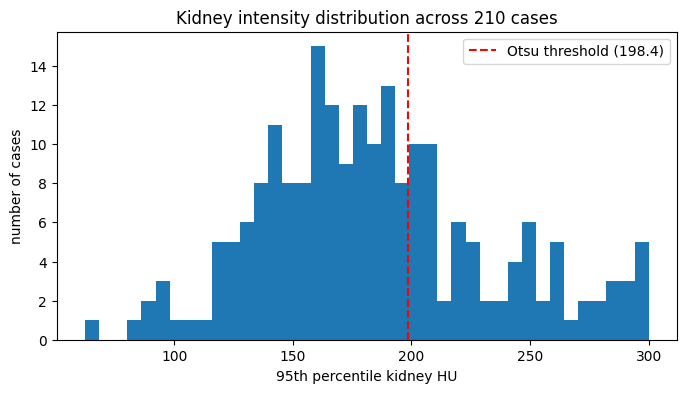

In [ ]:
def otsu_threshold(values):
    hist, bin_edges = np.histogram(values, bins=256)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    weight1 = np.cumsum(hist)
    weight2 = np.cumsum(hist[::-1])[::-1]

    mean1 = np.cumsum(hist * bin_centers) / np.maximum(weight1, 1)
    mean2 = (np.cumsum((hist * bin_centers)[::-1])[::-1]) / np.maximum(weight2, 1)

    inter_class_variance = weight1[:-1] * weight2[1:] * (mean1[:-1] - mean2[1:]) ** 2
    best_idx = np.argmax(inter_class_variance)
    return bin_centers[best_idx]


THRESHOLD = otsu_threshold(intensity_df["kidney_p95_hu"].values)
print(f"Otsu threshold: {THRESHOLD:.1f} HU")

plt.figure(figsize=(8, 4))
plt.hist(intensity_df["kidney_p95_hu"], bins=40)
plt.axvline(THRESHOLD, color="red", linestyle="--", label=f"Otsu threshold ({THRESHOLD:.1f})")
plt.xlabel("95th percentile kidney HU")
plt.ylabel("number of cases")
plt.title("Kidney intensity distribution across 210 cases")
plt.legend()
plt.show()


In [ ]:
intensity_df["modality_guess"] = np.where(
    intensity_df["kidney_p95_hu"] < THRESHOLD, "NCCT", "CECT"
)
print(intensity_df["modality_guess"].value_counts())


modality_guess
NCCT    140
CECT     70
Name: count, dtype: int64


In [ ]:
merged["modality_guess"] = intensity_df.set_index("case_id").loc[merged["case_id"], "modality_guess"].values
print(pd.crosstab(merged["split"], merged["modality_guess"]))

modality_guess  CECT  NCCT
split                     
test              13    19
train             46   100
val               11    21


# Experiments 1 & 2: CECT Baseline vs. NCCT Baseline

Trains two separate classifiers -- one on CECT-only cases, one on NCCT-only cases -- using
the exact same `KidneyPatchDataset`, `Simple3DCNN`, and `run_epoch` from Model 2. Nothing
about those is changed; only the case lists fed into them differ.

This answers RQ1 from the research plan: how does detection performance differ between
CECT and NCCT? It's also the "no transfer" baseline that Experiment 3 (CECT-to-NCCT
transfer) will later be compared against.

Run top to bottom. Requires `kidney_intensity_fingerprint.csv` and the Otsu threshold
result from the CSE437 notebook -- if you haven't run that yet (or deleted the bad
last cell and re-run), do that first.

## 1. Build modality-filtered case lists

Loads the modality fingerprint + Otsu threshold result, joins it onto the existing
train/val/test split, and writes six new case-list CSVs (train/val/test x CECT/NCCT)
into `kits19_processed/`. These have the exact same `case_id`-only schema as
`train_cases.csv` etc., so `KidneyPatchDataset` needs zero changes -- just point it
at these files instead.

Non-destructive: writes new files only, doesn't touch `merged_metadata.csv` or the
original split files.

In [ ]:
intensity_df = pd.read_csv(os.path.join(DATA_DIR, "kidney_intensity_fingerprint.csv"))
merged = pd.read_csv(os.path.join(DATA_DIR, "merged_metadata.csv"))


def otsu_threshold(values):
    hist, bin_edges = np.histogram(values, bins=256)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    weight1 = np.cumsum(hist)
    weight2 = np.cumsum(hist[::-1])[::-1]
    mean1 = np.cumsum(hist * bin_centers) / np.maximum(weight1, 1)
    mean2 = (np.cumsum((hist * bin_centers)[::-1])[::-1]) / np.maximum(weight2, 1)
    inter_class_variance = weight1[:-1] * weight2[1:] * (mean1[:-1] - mean2[1:]) ** 2
    return bin_centers[np.argmax(inter_class_variance)]


THRESHOLD = otsu_threshold(intensity_df["kidney_p95_hu"].values)
intensity_df["modality_guess"] = np.where(
    intensity_df["kidney_p95_hu"] < THRESHOLD, "NCCT", "CECT"
)

merged = merged.merge(intensity_df[["case_id", "modality_guess"]], on="case_id", how="left")
merged.to_csv(os.path.join(DATA_DIR, "case_modality.csv"), index=False)

print(f"Otsu threshold: {THRESHOLD:.1f} HU")
print(pd.crosstab(merged["split"], merged["modality_guess"]))

os.makedirs(os.path.join(DATA_DIR, "experiment_splits"), exist_ok=True)
for split in ["train", "val", "test"]:
    for modality in ["CECT", "NCCT"]:
        subset = merged[(merged["split"] == split) & (merged["modality_guess"] == modality)]
        out_path = os.path.join(
            DATA_DIR, "experiment_splits", f"{split}_cases_{modality.lower()}.csv"
        )
        subset[["case_id"]].to_csv(out_path, index=False)
        print(f"{out_path}: {len(subset)} cases")


Otsu threshold: 198.4 HU
modality_guess  CECT  NCCT
split                     
test              13    19
train             46   100
val               11    21
/content/drive/MyDrive/kits19_processed/experiment_splits/train_cases_cect.csv: 46 cases
/content/drive/MyDrive/kits19_processed/experiment_splits/train_cases_ncct.csv: 100 cases
/content/drive/MyDrive/kits19_processed/experiment_splits/val_cases_cect.csv: 11 cases
/content/drive/MyDrive/kits19_processed/experiment_splits/val_cases_ncct.csv: 21 cases
/content/drive/MyDrive/kits19_processed/experiment_splits/test_cases_cect.csv: 13 cases
/content/drive/MyDrive/kits19_processed/experiment_splits/test_cases_ncct.csv: 19 cases


## 2. Shared dataset, model, and training loop

Unchanged from Model 2 -- copied here so this notebook runs standalone.

In [ ]:
HU_MIN, HU_MAX = -200.0, 300.0
DEFAULT_PATCH_SIZE = (24, 48, 48)   # shrunk from (32,64,64) -- see diagnosis below
TUMOR_CENTER_FRAC = 0.5
MIN_TUMOR_VOXELS_FOR_POSITIVE = 10
MAX_RESAMPLE_ATTEMPTS = 20


def normalize(image):
    return (image - HU_MIN) / (HU_MAX - HU_MIN)


class KidneyPatchDataset(Dataset):
    def __init__(
        self,
        data_dir,
        split_csv,
        patch_size=DEFAULT_PATCH_SIZE,
        patches_per_epoch=2000,
        tumor_center_frac=TUMOR_CENTER_FRAC,
        preload=True,
        seed=None,  # if set, this dataset is FIXED -- same patches every epoch
    ):
        self.data_dir = data_dir
        self.patch_size = patch_size
        self.patches_per_epoch = patches_per_epoch
        self.tumor_center_frac = tumor_center_frac
        self.preload = preload
        self.seed = seed
        self._fallback_count = 0
        self._fallback_by_case = {}

        case_ids = pd.read_csv(os.path.join(data_dir, split_csv))["case_id"].tolist()
        self.case_ids = case_ids

        self._cache = {}
        if preload:
            for case_id in case_ids:
                self._cache[case_id] = self._load_case(case_id)

        self._tumor_coords = {}
        self._kidney_coords = {}
        for case_id in case_ids:
            _, mask = self._get_case(case_id)
            tumor_coords = np.argwhere(mask == 2)
            kidney_coords = np.argwhere(mask == 1)
            self._tumor_coords[case_id] = tumor_coords if len(tumor_coords) > 0 else kidney_coords
            self._kidney_coords[case_id] = kidney_coords if len(kidney_coords) > 0 else tumor_coords

        # If a seed is given, materialize the ENTIRE dataset once, up front,
        # using its own private RNG. Reproducible and fixed across epochs --
        # essential for a real validation/test set.
        self._fixed_items = None
        if self.seed is not None:
            rng = np.random.RandomState(self.seed)
            self._fixed_items = [self._draw_one(rng) for _ in range(self.patches_per_epoch)]

    def _load_case(self, case_id):
        image = np.load(os.path.join(self.data_dir, case_id, "image.npy"))
        mask = np.load(os.path.join(self.data_dir, case_id, "mask.npy"))
        return image, mask

    def _get_case(self, case_id):
        if self.preload:
            return self._cache[case_id]
        return self._load_case(case_id)

    def __len__(self):
        return self.patches_per_epoch

    def _extract_patch(self, image, mask, center):
        pd_, ph, pw = self.patch_size
        shape = image.shape

        def bounds(c, p, dim_size):
            start = int(c - p // 2)
            start = max(0, min(start, dim_size - p))
            return start, start + p

        z0, z1 = bounds(center[0], pd_, shape[0])
        y0, y1 = bounds(center[1], ph, shape[1])
        x0, x1 = bounds(center[2], pw, shape[2])

        image_patch = image[z0:z1, y0:y1, x0:x1]
        mask_patch = mask[z0:z1, y0:y1, x0:x1]
        return image_patch, mask_patch

    def _draw_one(self, rng):
        case_id = self.case_ids[rng.randint(len(self.case_ids))]
        image, mask = self._get_case(case_id)

        want_positive = rng.rand() < self.tumor_center_frac
        coords = self._tumor_coords[case_id] if want_positive else self._kidney_coords[case_id]

        image_patch = mask_patch = None
        label = 0
        matched = False
        for _ in range(MAX_RESAMPLE_ATTEMPTS):
            center = coords[rng.randint(len(coords))]
            candidate_image, candidate_mask = self._extract_patch(image, mask, center)
            tumor_voxel_count = int((candidate_mask == 2).sum())
            candidate_label = 1 if tumor_voxel_count >= MIN_TUMOR_VOXELS_FOR_POSITIVE else 0

            image_patch, mask_patch, label = candidate_image, candidate_mask, candidate_label
            if candidate_label == int(want_positive):
                matched = True
                break

        if not matched:
            self._fallback_count += 1
            self._fallback_by_case[case_id] = self._fallback_by_case.get(case_id, 0) + 1

        image_patch = normalize(image_patch).astype(np.float32)
        image_tensor = torch.from_numpy(image_patch).unsqueeze(0)
        label_tensor = torch.tensor(label, dtype=torch.float32)
        return image_tensor, label_tensor

    def __getitem__(self, idx):
        if self._fixed_items is not None:
            return self._fixed_items[idx]
        return self._draw_one(np.random)


def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    n_batches = 0
    all_probs = []
    all_labels = []

    with torch.set_grad_enabled(is_train):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item()
            n_batches += 1

            probs = torch.sigmoid(logits).detach().cpu().numpy()
            all_probs.extend(probs.tolist())
            all_labels.extend(labels.detach().cpu().numpy().tolist())

    preds = [1 if p >= 0.5 else 0 for p in all_probs]
    sensitivity = recall_score(all_labels, preds, zero_division=0)
    precision = precision_score(all_labels, preds, zero_division=0)
    f1 = f1_score(all_labels, preds, zero_division=0)
    try:
        auroc = roc_auc_score(all_labels, all_probs)
    except ValueError:
        auroc = float("nan")

    return {
        "loss": total_loss / n_batches,
        "sensitivity": sensitivity,
        "precision": precision,
        "f1": f1,
        "auroc": auroc,
    }


class Simple3DCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv3d(1, 16, 3, padding=1), nn.GroupNorm(4, 16), nn.ReLU(), nn.MaxPool3d(2),
            nn.Conv3d(16, 32, 3, padding=1), nn.GroupNorm(8, 32), nn.ReLU(), nn.MaxPool3d(2),
            nn.Conv3d(32, 64, 3, padding=1), nn.GroupNorm(8, 64), nn.ReLU(), nn.MaxPool3d(2),
        )
        self.pool = nn.AdaptiveAvgPool3d(1)
        self.classifier = nn.Linear(64, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        return self.classifier(x).squeeze(1)


## 3. Reusable training function

One function, called once per modality, so CECT and NCCT are trained identically --
same architecture, same hyperparameters, same number of epochs. Any performance
difference we see is attributable to the data, not to different training setups.

In [ ]:
def train_baseline(name, train_csv, val_csv, num_epochs=20,
                    train_patches=2000, val_patches=400, pos_weight_val=0.5625):
    print(f"\n===== Training {name} baseline =====")

    train_ds = KidneyPatchDataset(DATA_DIR, train_csv, patches_per_epoch=train_patches, preload=True)
    val_ds = KidneyPatchDataset(DATA_DIR, val_csv, patches_per_epoch=val_patches, preload=True, seed=42)
    train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

    model = Simple3DCNN().to(device)
    pos_weight = torch.tensor([pos_weight_val]).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
    scheduler = ReduceLROnPlateau(optimizer, mode="min", patience=2, factor=0.5)

    best_val_auroc = -1.0
    best_state = None
    history = []

    for epoch in range(1, num_epochs + 1):
        train_metrics = run_epoch(model, train_loader, criterion, optimizer)
        val_metrics = run_epoch(model, val_loader, criterion, optimizer=None)
        scheduler.step(val_metrics["loss"])

        if val_metrics["auroc"] > best_val_auroc:
            best_val_auroc = val_metrics["auroc"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        history.append({"epoch": epoch, **{f"train_{k}": v for k, v in train_metrics.items()},
                         **{f"val_{k}": v for k, v in val_metrics.items()}})

        current_lr = optimizer.param_groups[0]["lr"]
        print(f"[{name}] Epoch {epoch:2d} | lr {current_lr:.1e} | "
              f"train loss {train_metrics['loss']:.4f} | "
              f"val loss {val_metrics['loss']:.4f} sens {val_metrics['sensitivity']:.2f} "
              f"prec {val_metrics['precision']:.2f} f1 {val_metrics['f1']:.2f} "
              f"auroc {val_metrics['auroc']:.2f}")

    print(f"\n[{name}] Best val AUROC: {best_val_auroc:.3f}")
    torch.save(best_state, f"model2_{name.lower()}_baseline.pt")
    return {"name": name, "best_val_auroc": best_val_auroc, "history": pd.DataFrame(history)}


## 4. Experiment 1 — CECT baseline

Trains on the 46 CECT training cases. Fewer cases than NCCT -- watch train/val loss
gap for signs of overfitting more closely than on the NCCT run.

In [ ]:
cect_train_csv = "experiment_splits/train_cases_cect.csv"  # relative to DATA_DIR
cect_val_csv = "experiment_splits/val_cases_cect.csv"

cect_result = train_baseline("CECT", cect_train_csv, cect_val_csv)


===== Training CECT baseline =====
[CECT] Epoch  1 | lr 5.0e-04 | train loss 0.5190 | val loss 0.5202 sens 0.00 prec 0.00 f1 0.00 auroc 0.50
[CECT] Epoch  2 | lr 5.0e-04 | train loss 0.5091 | val loss 0.5144 sens 0.00 prec 0.00 f1 0.00 auroc 0.56
[CECT] Epoch  3 | lr 5.0e-04 | train loss 0.5007 | val loss 0.5189 sens 0.18 prec 0.72 f1 0.29 auroc 0.53
[CECT] Epoch  4 | lr 5.0e-04 | train loss 0.4966 | val loss 0.5009 sens 0.61 prec 0.70 f1 0.65 auroc 0.59
[CECT] Epoch  5 | lr 5.0e-04 | train loss 0.4794 | val loss 0.5300 sens 0.72 prec 0.63 f1 0.67 auroc 0.57
[CECT] Epoch  6 | lr 5.0e-04 | train loss 0.4959 | val loss 0.5211 sens 0.35 prec 0.59 f1 0.44 auroc 0.52
[CECT] Epoch  7 | lr 2.5e-04 | train loss 0.4816 | val loss 0.5103 sens 0.58 prec 0.70 f1 0.63 auroc 0.58
[CECT] Epoch  8 | lr 2.5e-04 | train loss 0.4757 | val loss 0.5220 sens 0.40 prec 0.67 f1 0.50 auroc 0.55
[CECT] Epoch  9 | lr 2.5e-04 | train loss 0.4647 | val loss 0.5025 sens 0.60 prec 0.69 f1 0.64 auroc 0.60
[CECT] Epo

## 5. Experiment 2 — NCCT baseline

Same setup, trained on the 100 NCCT training cases.

In [ ]:
ncct_train_csv = "experiment_splits/train_cases_ncct.csv"  # relative to DATA_DIR
ncct_val_csv = "experiment_splits/val_cases_ncct.csv"

ncct_result = train_baseline("NCCT", ncct_train_csv, ncct_val_csv)


===== Training NCCT baseline =====
[NCCT] Epoch  1 | lr 5.0e-04 | train loss 0.4925 | val loss 0.4985 sens 0.14 prec 0.56 f1 0.23 auroc 0.57
[NCCT] Epoch  2 | lr 5.0e-04 | train loss 0.4863 | val loss 0.5164 sens 0.04 prec 1.00 f1 0.08 auroc 0.55
[NCCT] Epoch  3 | lr 5.0e-04 | train loss 0.4771 | val loss 0.5087 sens 0.14 prec 0.61 f1 0.23 auroc 0.55
[NCCT] Epoch  4 | lr 2.5e-04 | train loss 0.4656 | val loss 0.5080 sens 0.62 prec 0.66 f1 0.64 auroc 0.55
[NCCT] Epoch  5 | lr 2.5e-04 | train loss 0.4666 | val loss 0.5181 sens 0.49 prec 0.68 f1 0.57 auroc 0.56
[NCCT] Epoch  6 | lr 2.5e-04 | train loss 0.4550 | val loss 0.4924 sens 0.34 prec 0.72 f1 0.46 auroc 0.55
[NCCT] Epoch  7 | lr 2.5e-04 | train loss 0.4567 | val loss 0.5046 sens 0.15 prec 0.81 f1 0.25 auroc 0.55
[NCCT] Epoch  8 | lr 2.5e-04 | train loss 0.4404 | val loss 0.4974 sens 0.18 prec 0.83 f1 0.29 auroc 0.58
[NCCT] Epoch  9 | lr 2.5e-04 | train loss 0.4433 | val loss 0.4914 sens 0.52 prec 0.69 f1 0.59 auroc 0.58
[NCCT] Epo

## 6. Compare: RQ1

How does detection performance differ between CECT and NCCT? This is the first real
answer to that question, and the reference point Experiment 3 (CECT-to-NCCT transfer)
will be compared against later.

CECT baseline best val AUROC: 0.632
NCCT baseline best val AUROC: 0.729


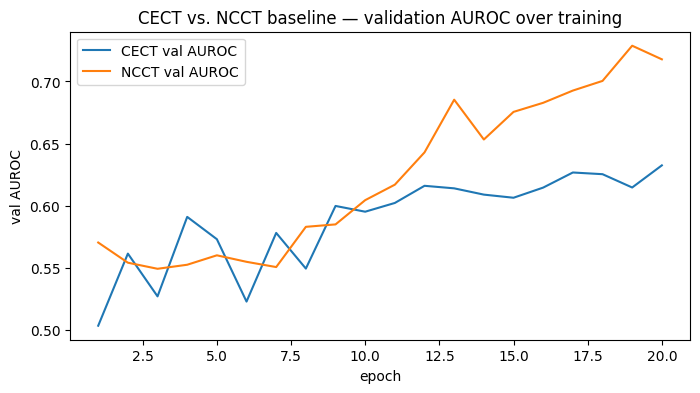

In [ ]:
print(f"CECT baseline best val AUROC: {cect_result['best_val_auroc']:.3f}")
print(f"NCCT baseline best val AUROC: {ncct_result['best_val_auroc']:.3f}")

plt.figure(figsize=(8, 4))
plt.plot(cect_result["history"]["epoch"], cect_result["history"]["val_auroc"], label="CECT val AUROC")
plt.plot(ncct_result["history"]["epoch"], ncct_result["history"]["val_auroc"], label="NCCT val AUROC")
plt.xlabel("epoch")
plt.ylabel("val AUROC")
plt.title("CECT vs. NCCT baseline — validation AUROC over training")
plt.legend()
plt.show()

# Experiment 3: CECT-to-NCCT Transfer Learning

Loads the weights from the CECT baseline (Experiment 1), uses them as the starting point
for a model trained on NCCT (instead of random initialization), and compares the result
against the NCCT-from-scratch baseline (Experiment 2).

This is the core test of RQ2: does CECT pretraining improve NCCT detection compared to
training from scratch on NCCT alone?

**Design note:** every hyperparameter (learning rate, scheduler, epochs, batch size) is
kept identical to Experiment 2's NCCT baseline. The *only* difference is the starting
weights. That's intentional -- it isolates pretraining as the one variable being tested,
same principle used for the Experiment 1 vs. 2 comparison.

Paste these cells at the end of your existing notebook (after Experiments 1 & 2) --
this assumes `KidneyPatchDataset`, `run_epoch`, `Simple3DCNN`, `train_baseline`, `DATA_DIR`,
and `device` are already defined from those earlier cells in the same session. If you're
running this fresh in a new session instead, run Experiments 1 & 2 first so
`model2_cect_baseline.pt` exists.

## 1. Back up checkpoints to Drive

`model2_cect_baseline.pt` and `model2_ncct_baseline.pt` were saved to Colab's local disk
in the Experiment 1/2 cells -- which disappears if the runtime disconnects. Copying them
to Drive now means you don't lose them if that happens before you finish this notebook.

In [ ]:
os.makedirs(os.path.join(DATA_DIR, "checkpoints"), exist_ok=True)

for fname in ["model2_cect_baseline.pt", "model2_ncct_baseline.pt"]:
    if os.path.exists(fname):
        shutil.copy(fname, os.path.join(DATA_DIR, "checkpoints", fname))
        print(f"Backed up {fname} to Drive")
    else:
        print(f"WARNING: {fname} not found locally -- re-run Experiments 1/2 first")

Backed up model2_cect_baseline.pt to Drive
Backed up model2_ncct_baseline.pt to Drive


## 2. Transfer training function

Same as `train_baseline`, but takes a `pretrained_path` and loads those weights into the
model before training starts, instead of random initialization.

In [ ]:
def train_transfer(name, train_csv, val_csv, pretrained_path, num_epochs=20,
                    train_patches=2000, val_patches=400, pos_weight_val=0.5625):
    print(f"\n===== Training {name} (pretrained from {pretrained_path}) =====")

    train_ds = KidneyPatchDataset(DATA_DIR, train_csv, patches_per_epoch=train_patches, preload=True)
    val_ds = KidneyPatchDataset(DATA_DIR, val_csv, patches_per_epoch=val_patches, preload=True, seed=42)
    train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

    model = Simple3DCNN().to(device)
    pretrained_state = torch.load(pretrained_path, map_location=device)
    model.load_state_dict(pretrained_state)
    print(f"Loaded pretrained weights from {pretrained_path}")

    pos_weight = torch.tensor([pos_weight_val]).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)  # identical to train_baseline -- see design note above
    scheduler = ReduceLROnPlateau(optimizer, mode="min", patience=2, factor=0.5)

    best_val_auroc = -1.0
    best_state = None
    history = []

    for epoch in range(1, num_epochs + 1):
        train_metrics = run_epoch(model, train_loader, criterion, optimizer)
        val_metrics = run_epoch(model, val_loader, criterion, optimizer=None)
        scheduler.step(val_metrics["loss"])

        if val_metrics["auroc"] > best_val_auroc:
            best_val_auroc = val_metrics["auroc"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        history.append({"epoch": epoch, **{f"train_{k}": v for k, v in train_metrics.items()},
                         **{f"val_{k}": v for k, v in val_metrics.items()}})

        current_lr = optimizer.param_groups[0]["lr"]
        print(f"[{name}] Epoch {epoch:2d} | lr {current_lr:.1e} | "
              f"train loss {train_metrics['loss']:.4f} | "
              f"val loss {val_metrics['loss']:.4f} sens {val_metrics['sensitivity']:.2f} "
              f"prec {val_metrics['precision']:.2f} f1 {val_metrics['f1']:.2f} "
              f"auroc {val_metrics['auroc']:.2f}")

    print(f"\n[{name}] Best val AUROC: {best_val_auroc:.3f}")
    ckpt_name = f"model2_{name.lower()}_baseline.pt"
    torch.save(best_state, ckpt_name)
    shutil.copy(ckpt_name, os.path.join(DATA_DIR, "checkpoints", ckpt_name))
    return {"name": name, "best_val_auroc": best_val_auroc, "history": pd.DataFrame(history),
            "checkpoint": ckpt_name}

## 3. Run the transfer experiment

Trains on the same NCCT training cases and same NCCT val cases as Experiment 2 --
starting from `model2_cect_baseline.pt` instead of random weights.

In [ ]:
ncct_train_csv = "experiment_splits/train_cases_ncct.csv"
ncct_val_csv = "experiment_splits/val_cases_ncct.csv"

transfer_result = train_transfer(
    "Transfer_CECT_to_NCCT",
    ncct_train_csv,
    ncct_val_csv,
    pretrained_path="model2_cect_baseline.pt",
)


===== Training Transfer_CECT_to_NCCT (pretrained from model2_cect_baseline.pt) =====
Loaded pretrained weights from model2_cect_baseline.pt
[Transfer_CECT_to_NCCT] Epoch  1 | lr 5.0e-04 | train loss 0.4789 | val loss 0.5061 sens 0.18 prec 0.75 f1 0.28 auroc 0.55
[Transfer_CECT_to_NCCT] Epoch  2 | lr 5.0e-04 | train loss 0.4703 | val loss 0.5129 sens 0.30 prec 0.66 f1 0.41 auroc 0.55
[Transfer_CECT_to_NCCT] Epoch  3 | lr 5.0e-04 | train loss 0.4563 | val loss 0.4862 sens 0.37 prec 0.76 f1 0.50 auroc 0.61
[Transfer_CECT_to_NCCT] Epoch  4 | lr 5.0e-04 | train loss 0.4628 | val loss 0.4940 sens 0.51 prec 0.70 f1 0.59 auroc 0.59
[Transfer_CECT_to_NCCT] Epoch  5 | lr 5.0e-04 | train loss 0.4487 | val loss 0.5229 sens 0.84 prec 0.69 f1 0.76 auroc 0.60
[Transfer_CECT_to_NCCT] Epoch  6 | lr 5.0e-04 | train loss 0.4598 | val loss 0.4861 sens 0.54 prec 0.70 f1 0.61 auroc 0.60
[Transfer_CECT_to_NCCT] Epoch  7 | lr 5.0e-04 | train loss 0.4437 | val loss 0.5078 sens 0.86 prec 0.66 f1 0.74 auroc 0.6

## 4. Compare: RQ2 -- transfer vs. from-scratch on NCCT

Both trained/validated on identical NCCT data with identical hyperparameters. Any
difference here is attributable to the CECT pretraining.

NCCT from-scratch best val AUROC: 0.729
NCCT transfer (CECT-pretrained) best val AUROC: 0.720


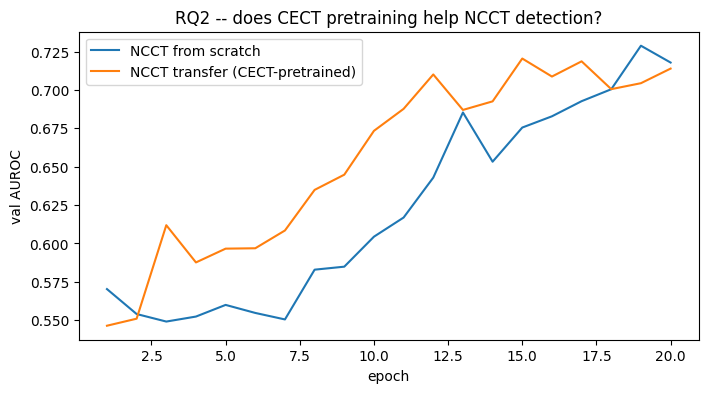

In [ ]:
print(f"NCCT from-scratch best val AUROC: {ncct_result['best_val_auroc']:.3f}")
print(f"NCCT transfer (CECT-pretrained) best val AUROC: {transfer_result['best_val_auroc']:.3f}")

plt.figure(figsize=(8, 4))
plt.plot(ncct_result["history"]["epoch"], ncct_result["history"]["val_auroc"], label="NCCT from scratch")
plt.plot(transfer_result["history"]["epoch"], transfer_result["history"]["val_auroc"], label="NCCT transfer (CECT-pretrained)")
plt.xlabel("epoch")
plt.ylabel("val AUROC")
plt.title("RQ2 -- does CECT pretraining help NCCT detection?")
plt.legend()
plt.show()


## 5. Final test-set evaluation

Val AUROC was used to pick each "best" checkpoint during training, so it's mildly
optimistic by construction. These are the untouched test sets, evaluated once, for the
honest final numbers.

- CECT baseline -> evaluated on the CECT test set (its own modality)
- NCCT baseline -> evaluated on the NCCT test set
- Transfer model -> evaluated on the **same** NCCT test set as the NCCT baseline, for a
  fair, apples-to-apples RQ2 comparison

In [ ]:
def evaluate_checkpoint(checkpoint_path, test_csv, test_patches=400, seed=123):
    model = Simple3DCNN().to(device)
    state = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(state)

    test_ds = KidneyPatchDataset(DATA_DIR, test_csv, patches_per_epoch=test_patches, preload=True, seed=seed)
    test_loader = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

    criterion = nn.BCEWithLogitsLoss()  # unweighted -- doesn't affect predictions, only loss magnitude
    return run_epoch(model, test_loader, criterion, optimizer=None)


cect_test_metrics = evaluate_checkpoint("model2_cect_baseline.pt", "experiment_splits/test_cases_cect.csv")
ncct_test_metrics = evaluate_checkpoint("model2_ncct_baseline.pt", "experiment_splits/test_cases_ncct.csv")
transfer_test_metrics = evaluate_checkpoint(transfer_result["checkpoint"], "experiment_splits/test_cases_ncct.csv")

summary = pd.DataFrame([
    {"experiment": "Exp 1: CECT baseline", "test_set": "CECT test", **cect_test_metrics},
    {"experiment": "Exp 2: NCCT from scratch", "test_set": "NCCT test", **ncct_test_metrics},
    {"experiment": "Exp 3: NCCT transfer (CECT-pretrained)", "test_set": "NCCT test", **transfer_test_metrics},
])
summary = summary[["experiment", "test_set", "auroc", "sensitivity", "precision", "f1", "loss"]]
print(summary.to_string(index=False))

summary.to_csv(os.path.join(DATA_DIR, "results_summary_exp1_2_3.csv"), index=False)
print(f"\nSaved to {os.path.join(DATA_DIR, 'results_summary_exp1_2_3.csv')}")


                            experiment  test_set    auroc  sensitivity  precision       f1     loss
                  Exp 1: CECT baseline CECT test 0.685335     0.607306   0.651961 0.628842 0.633801
              Exp 2: NCCT from scratch NCCT test 0.770743     0.796813   0.793651 0.795229 0.569846
Exp 3: NCCT transfer (CECT-pretrained) NCCT test 0.753095     0.653386   0.792271 0.716157 0.595486

Saved to /content/drive/MyDrive/kits19_processed/results_summary_exp1_2_3.csv


# Experiment 4: Size-Stratified Evaluation (RQ3)

Tests RQ3 directly: is the CECT-to-NCCT transfer benefit larger for small tumors than
large ones? The aggregate test-set numbers from Experiment 3 showed almost no difference
overall (0.774 vs. 0.769 AUROC) -- but your research plan's actual hypothesis is about
the *small-tumor subgroup specifically*, not the aggregate. This could reveal a real
effect that's hidden inside the overall wash.

**Design:** rather than randomly sampling patches across all test cases (which could
under-represent some cases by chance), this draws a fixed number of patches from
*every* NCCT test case individually, tags each patch with its case's `tumor_size_group`,
then computes AUROC/sensitivity/precision/F1 separately per group for both the
NCCT-from-scratch model and the transfer model.

**Important caveat up front:** your NCCT test set only has 19 cases total, and Small
tumors are the rarest group in your whole dataset (22 of 210 cases). The Small-tumor
subgroup here will likely be only 1-3 cases. Treat any Small-group result as a
preliminary signal, not a statistically established finding -- the per-group case
counts are printed explicitly below so you can see exactly how thin each group is
before interpreting the numbers.

Paste at the end of your notebook -- assumes `Simple3DCNN`, `DATA_DIR`, `device`,
`merged`, `normalize`, `HU_MIN`, `HU_MAX`, `DEFAULT_PATCH_SIZE`, `TUMOR_CENTER_FRAC`,
`MIN_TUMOR_VOXELS_FOR_POSITIVE`, `MAX_RESAMPLE_ATTEMPTS`, and `transfer_result` are
already defined from the earlier cells in this session.

## 1. Per-case, fixed-seed patch sampling

A standalone function (doesn't touch `KidneyPatchDataset`) that draws a fixed number of
patches from one specific case, using the same sampling logic (50/50 tumor/kidney-center
draw, retry until the target label is hit or `MAX_RESAMPLE_ATTEMPTS` is exhausted) --
just scoped to a single case instead of randomly picking a case per patch, so every test
case is guaranteed to contribute patches.

In [ ]:
def extract_patch(image, mask, center, patch_size):
    pd_, ph, pw = patch_size
    shape = image.shape

    def bounds(c, p, dim_size):
        start = int(c - p // 2)
        start = max(0, min(start, dim_size - p))
        return start, start + p

    z0, z1 = bounds(center[0], pd_, shape[0])
    y0, y1 = bounds(center[1], ph, shape[1])
    x0, x1 = bounds(center[2], pw, shape[2])
    return image[z0:z1, y0:y1, x0:x1], mask[z0:z1, y0:y1, x0:x1]


def sample_fixed_patches_for_case(case_id, n_patches, seed):
    image = np.load(os.path.join(DATA_DIR, case_id, "image.npy"))
    mask = np.load(os.path.join(DATA_DIR, case_id, "mask.npy"))

    tumor_coords = np.argwhere(mask == 2)
    kidney_coords = np.argwhere(mask == 1)
    if len(tumor_coords) == 0:
        tumor_coords = kidney_coords
    if len(kidney_coords) == 0:
        kidney_coords = tumor_coords

    rng = np.random.RandomState(seed)
    patches = []
    for _ in range(n_patches):
        want_positive = rng.rand() < TUMOR_CENTER_FRAC
        coords = tumor_coords if want_positive else kidney_coords

        image_patch = mask_patch = None
        label = 0
        for _ in range(MAX_RESAMPLE_ATTEMPTS):
            center = coords[rng.randint(len(coords))]
            cand_image, cand_mask = extract_patch(image, mask, center, DEFAULT_PATCH_SIZE)
            tumor_voxel_count = int((cand_mask == 2).sum())
            cand_label = 1 if tumor_voxel_count >= MIN_TUMOR_VOXELS_FOR_POSITIVE else 0
            image_patch, mask_patch, label = cand_image, cand_mask, cand_label
            if cand_label == int(want_positive):
                break

        image_patch = normalize(image_patch).astype(np.float32)
        image_tensor = torch.from_numpy(image_patch).unsqueeze(0)
        patches.append((image_tensor, torch.tensor(label, dtype=torch.float32)))

    return patches


## 2. Stratified evaluation function

Runs a checkpoint over every case in a test set, `patches_per_case` patches each, and
returns one row per patch with its `tumor_size_group` attached -- so metrics can be
computed per group afterward.

In [ ]:
def evaluate_stratified(checkpoint_path, test_case_ids, patches_per_case=30, seed=123):
    model = Simple3DCNN().to(device)
    state = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(state)
    model.eval()

    size_lookup = dict(zip(merged["case_id"], merged["tumor_size_group"]))

    records = []
    with torch.no_grad():
        for case_id in test_case_ids:
            patches = sample_fixed_patches_for_case(case_id, patches_per_case, seed)
            images = torch.stack([p[0] for p in patches]).to(device)
            labels = torch.stack([p[1] for p in patches]).to(device)

            probs = torch.sigmoid(model(images)).cpu().numpy()
            labels_np = labels.cpu().numpy()

            for prob, label in zip(probs, labels_np):
                records.append({
                    "case_id": case_id,
                    "tumor_size_group": size_lookup.get(case_id, "unknown"),
                    "prob": float(prob),
                    "label": float(label),
                })

    return pd.DataFrame(records)


def metrics_by_group(patch_df):
    rows = []
    for group, sub in patch_df.groupby("tumor_size_group"):
        preds = (sub["prob"] >= 0.5).astype(int)
        sens = recall_score(sub["label"], preds, zero_division=0)
        prec = precision_score(sub["label"], preds, zero_division=0)
        f1 = f1_score(sub["label"], preds, zero_division=0)
        try:
            auroc = roc_auc_score(sub["label"], sub["prob"])
        except ValueError:
            auroc = float("nan")  # only one class present -- can happen in tiny groups
        rows.append({
            "tumor_size_group": group,
            "n_cases": sub["case_id"].nunique(),
            "n_patches": len(sub),
            "auroc": auroc,
            "sensitivity": sens,
            "precision": prec,
            "f1": f1,
        })
    return pd.DataFrame(rows)


## 3. Run stratified evaluation for both models

Same NCCT test case list for both, so the comparison is apples-to-apples -- same
principle used throughout Experiments 1-3.

In [ ]:
ncct_test_case_ids = pd.read_csv(
    os.path.join(DATA_DIR, "experiment_splits", "test_cases_ncct.csv")
)["case_id"].tolist()

print(f"NCCT test cases: {len(ncct_test_case_ids)}")
print("Tumor size group counts in this test set:")
print(merged[merged["case_id"].isin(ncct_test_case_ids)]["tumor_size_group"].value_counts())

scratch_patches = evaluate_stratified("model2_ncct_baseline.pt", ncct_test_case_ids)
transfer_patches = evaluate_stratified(transfer_result["checkpoint"], ncct_test_case_ids)

scratch_by_group = metrics_by_group(scratch_patches)
transfer_by_group = metrics_by_group(transfer_patches)

print("\nNCCT from-scratch, by tumor size group:")
print(scratch_by_group.to_string(index=False))

print("\nNCCT transfer (CECT-pretrained), by tumor size group:")
print(transfer_by_group.to_string(index=False))


NCCT test cases: 19
Tumor size group counts in this test set:
tumor_size_group
Large (>=40 mm)      12
Medium (20-40 mm)     7
Name: count, dtype: int64

NCCT from-scratch, by tumor size group:
 tumor_size_group  n_cases  n_patches    auroc  sensitivity  precision       f1
  Large (>=40 mm)       12        360 0.887934     0.912698   0.871212 0.891473
Medium (20-40 mm)        7        210 0.453045     0.413793   0.607595 0.492308

NCCT transfer (CECT-pretrained), by tumor size group:
 tumor_size_group  n_cases  n_patches    auroc  sensitivity  precision       f1
  Large (>=40 mm)       12        360 0.847002     0.789683   0.880531 0.832636
Medium (20-40 mm)        7        210 0.488261     0.293103   0.557377 0.384181


## 4. Compare side by side

`n_cases` is printed alongside every number -- treat any group with only 1-2 cases as a
preliminary observation, not a conclusion.

 tumor_size_group  n_cases_scratch  auroc_scratch  auroc_transfer  auroc_delta
Medium (20-40 mm)                7       0.453045        0.488261     0.035216
  Large (>=40 mm)               12       0.887934        0.847002    -0.040932


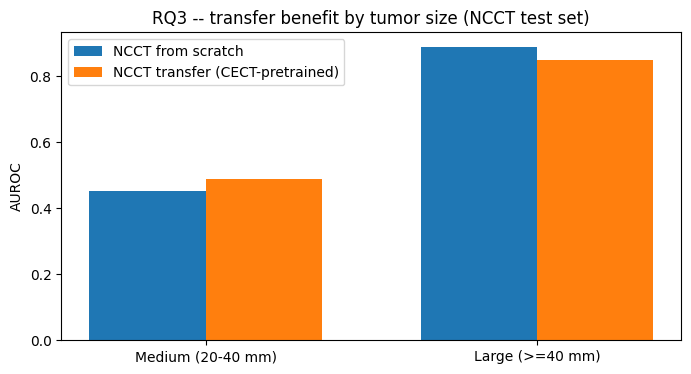


Saved to /content/drive/MyDrive/kits19_processed/results_summary_exp4_size_stratified.csv


In [ ]:
comparison = scratch_by_group.merge(
    transfer_by_group, on="tumor_size_group", suffixes=("_scratch", "_transfer")
)
comparison["auroc_delta"] = comparison["auroc_transfer"] - comparison["auroc_scratch"]

size_order = ["Small (<20 mm)", "Medium (20-40 mm)", "Large (>=40 mm)"]
comparison["tumor_size_group"] = pd.Categorical(comparison["tumor_size_group"], categories=size_order, ordered=True)
comparison = comparison.sort_values("tumor_size_group")

print(comparison[["tumor_size_group", "n_cases_scratch", "auroc_scratch", "auroc_transfer", "auroc_delta"]].to_string(index=False))

plt.figure(figsize=(8, 4))
x = np.arange(len(comparison))
width = 0.35
plt.bar(x - width/2, comparison["auroc_scratch"], width, label="NCCT from scratch")
plt.bar(x + width/2, comparison["auroc_transfer"], width, label="NCCT transfer (CECT-pretrained)")
plt.xticks(x, comparison["tumor_size_group"])
plt.ylabel("AUROC")
plt.title("RQ3 -- transfer benefit by tumor size (NCCT test set)")
plt.legend()
plt.show()

comparison.to_csv(os.path.join(DATA_DIR, "results_summary_exp4_size_stratified.csv"), index=False)
print(f"\nSaved to {os.path.join(DATA_DIR, 'results_summary_exp4_size_stratified.csv')}")


# Experiment 5: Failure Analysis (RQ4)

Investigates *why* detection fails where it fails -- directly testing RQ4 ("what tumor
characteristics are associated with false-negative predictions?") and digging into the
Medium-tumor anomaly from Experiment 4 (AUROC ~0.46-0.52, near chance, vs. ~0.87-0.89
for Large).

Three angles, each cheap since no retraining is involved -- this all runs on the models
you already trained:

1. **Per-case breakdown** -- is Medium's weak aggregate score spread across all 7 cases,
   or driven by 1-2 particularly bad ones?
2. **Patch-sampling fallback rate by size group** -- rules out (or confirms) that the
   Medium result is a sampling artifact rather than a real detection weakness.
3. **Intensity-contrast analysis of false negatives** -- tests the "isodensity tumor"
   hypothesis directly from your own lit review (Hatsutani et al.): do missed tumors
   have lower tumor-vs-kidney HU contrast than correctly detected ones?

Paste at the end of your notebook -- assumes everything from Experiments 1-4 is still
defined in this session (`Simple3DCNN`, `DATA_DIR`, `device`, `merged`, `normalize`,
`HU_MIN`, `HU_MAX`, `DEFAULT_PATCH_SIZE`, `TUMOR_CENTER_FRAC`,
`MIN_TUMOR_VOXELS_FOR_POSITIVE`, `MAX_RESAMPLE_ATTEMPTS`, `ncct_test_case_ids`,
`transfer_result`).

## 1. Diagnostic patch sampler

Same sampling logic as Experiment 4's `sample_fixed_patches_for_case`, but also records,
per patch: whether the retry loop actually matched its target label (fallback flag), the
raw (pre-normalization) mean HU of the patch, and -- when the patch contains tumor --
the HU contrast between tumor voxels and surrounding kidney voxels. That contrast number
is the direct test of the isodensity hypothesis: low contrast means the tumor barely
differs in brightness from normal kidney, which is exactly the failure mode Hatsutani et
al. describe.

A separate function from Experiment 4's, so nothing there is modified.

In [ ]:
def sample_fixed_patches_for_case_diag(case_id, n_patches, seed):
    image = np.load(os.path.join(DATA_DIR, case_id, "image.npy"))
    mask = np.load(os.path.join(DATA_DIR, case_id, "mask.npy"))

    tumor_coords = np.argwhere(mask == 2)
    kidney_coords = np.argwhere(mask == 1)
    if len(tumor_coords) == 0:
        tumor_coords = kidney_coords
    if len(kidney_coords) == 0:
        kidney_coords = tumor_coords

    rng = np.random.RandomState(seed)
    records = []
    for _ in range(n_patches):
        want_positive = rng.rand() < TUMOR_CENTER_FRAC
        coords = tumor_coords if want_positive else kidney_coords

        image_patch = mask_patch = None
        label = 0
        matched = False
        for _ in range(MAX_RESAMPLE_ATTEMPTS):
            center = coords[rng.randint(len(coords))]
            cand_image, cand_mask = extract_patch(image, mask, center, DEFAULT_PATCH_SIZE)
            tumor_voxel_count = int((cand_mask == 2).sum())
            cand_label = 1 if tumor_voxel_count >= MIN_TUMOR_VOXELS_FOR_POSITIVE else 0
            image_patch, mask_patch, label = cand_image, cand_mask, cand_label
            if cand_label == int(want_positive):
                matched = True
                break

        tumor_voxel_count = int((mask_patch == 2).sum())
        kidney_only_voxels = image_patch[mask_patch == 1]
        tumor_only_voxels = image_patch[mask_patch == 2]

        contrast_hu = (
            float(tumor_only_voxels.mean() - kidney_only_voxels.mean())
            if tumor_voxel_count > 0 and kidney_only_voxels.size > 0
            else np.nan
        )

        raw_mean_hu = float(image_patch.mean())
        raw_std_hu = float(image_patch.std())

        normalized_patch = normalize(image_patch).astype(np.float32)
        image_tensor = torch.from_numpy(normalized_patch).unsqueeze(0)

        records.append({
            "image_tensor": image_tensor,
            "label": label,
            "matched": matched,
            "tumor_voxel_count": tumor_voxel_count,
            "contrast_hu": contrast_hu,
            "raw_mean_hu": raw_mean_hu,
            "raw_std_hu": raw_std_hu,
        })

    return records


## 2. Run diagnostic evaluation

Same NCCT test cases as Experiment 4, both models, but now with the extra diagnostic
columns attached to every patch.

In [ ]:
def evaluate_diag(checkpoint_path, test_case_ids, patches_per_case=30, seed=123):
    model = Simple3DCNN().to(device)
    state = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(state)
    model.eval()

    size_lookup = dict(zip(merged["case_id"], merged["tumor_size_group"]))

    rows = []
    with torch.no_grad():
        for case_id in test_case_ids:
            records = sample_fixed_patches_for_case_diag(case_id, patches_per_case, seed)
            images = torch.stack([r["image_tensor"] for r in records]).to(device)
            probs = torch.sigmoid(model(images)).cpu().numpy()

            for r, prob in zip(records, probs):
                rows.append({
                    "case_id": case_id,
                    "tumor_size_group": size_lookup.get(case_id, "unknown"),
                    "prob": float(prob),
                    "label": r["label"],
                    "matched": r["matched"],
                    "tumor_voxel_count": r["tumor_voxel_count"],
                    "contrast_hu": r["contrast_hu"],
                    "raw_mean_hu": r["raw_mean_hu"],
                    "raw_std_hu": r["raw_std_hu"],
                })

    df = pd.DataFrame(rows)
    df["pred"] = (df["prob"] >= 0.5).astype(int)
    df["outcome"] = np.select(
        [
            (df["label"] == 1) & (df["pred"] == 1),
            (df["label"] == 1) & (df["pred"] == 0),
            (df["label"] == 0) & (df["pred"] == 1),
            (df["label"] == 0) & (df["pred"] == 0),
        ],
        ["TP", "FN", "FP", "TN"],
        default="unknown",
    )
    return df


scratch_diag = evaluate_diag("model2_ncct_baseline.pt", ncct_test_case_ids)
transfer_diag = evaluate_diag(transfer_result["checkpoint"], ncct_test_case_ids)

print("NCCT from-scratch -- outcome counts:")
print(scratch_diag["outcome"].value_counts())
print("\nNCCT transfer -- outcome counts:")
print(transfer_diag["outcome"].value_counts())


NCCT from-scratch -- outcome counts:
outcome
TP    278
TN    137
FN     90
FP     65
Name: count, dtype: int64

NCCT transfer -- outcome counts:
outcome
TP    233
TN    148
FN    135
FP     54
Name: count, dtype: int64


## 3. Per-case breakdown

Is Medium's weak aggregate AUROC spread across all 7 cases, or driven by a couple of
particularly hard ones? Reports per-case accuracy (not AUROC -- 30 patches per case is
too few for a stable per-case AUROC) and fallback rate side by side.

In [ ]:
def per_case_summary(df):
    rows = []
    for case_id, sub in df.groupby("case_id"):
        rows.append({
            "case_id": case_id,
            "tumor_size_group": sub["tumor_size_group"].iloc[0],
            "n_patches": len(sub),
            "accuracy": (sub["pred"] == sub["label"]).mean(),
            "fallback_rate": (~sub["matched"]).mean(),
        })
    return pd.DataFrame(rows).sort_values(["tumor_size_group", "accuracy"])


print("NCCT from-scratch, per case:")
print(per_case_summary(scratch_diag).to_string(index=False))

print("\nNCCT transfer, per case:")
print(per_case_summary(transfer_diag).to_string(index=False))


NCCT from-scratch, per case:
   case_id  tumor_size_group  n_patches  accuracy  fallback_rate
case_00126   Large (>=40 mm)         30  0.500000       0.000000
case_00005   Large (>=40 mm)         30  0.533333       0.000000
case_00149   Large (>=40 mm)         30  0.800000       0.033333
case_00176   Large (>=40 mm)         30  0.866667       0.000000
case_00045   Large (>=40 mm)         30  0.900000       0.466667
case_00108   Large (>=40 mm)         30  0.900000       0.166667
case_00192   Large (>=40 mm)         30  0.900000       0.766667
case_00204   Large (>=40 mm)         30  0.900000       0.033333
case_00046   Large (>=40 mm)         30  0.933333       0.166667
case_00107   Large (>=40 mm)         30  0.933333       0.600000
case_00181   Large (>=40 mm)         30  0.966667       0.000000
case_00008   Large (>=40 mm)         30  1.000000       0.366667
case_00093 Medium (20-40 mm)         30  0.266667       0.000000
case_00006 Medium (20-40 mm)         30  0.333333       0.000

## 4. Fallback rate by tumor size group

If Medium cases have a much higher fallback rate than Large, the weak Medium score could
be partly a sampling artifact (noisier/mislabeled-by-construction patches), not purely a
detection weakness. If fallback rates are similar across groups, that rules this out.

In [ ]:
fallback_by_group = (
    scratch_diag.groupby("tumor_size_group")["matched"]
    .apply(lambda s: (~s).mean())
    .rename("fallback_rate")
    .reset_index()
)
print("Fallback rate by tumor size group (NCCT test set):")
print(fallback_by_group.to_string(index=False))


Fallback rate by tumor size group (NCCT test set):
 tumor_size_group  fallback_rate
  Large (>=40 mm)       0.216667
Medium (20-40 mm)       0.000000


## 5. Isodensity hypothesis: intensity contrast of false negatives

Compares tumor-vs-kidney HU contrast between correctly detected tumors (TP) and missed
tumors (FN). If FN patches show *lower* contrast on average, that's direct evidence for
the isodensity failure mode described in your lit review -- the model is missing tumors
specifically when they don't stand out in brightness from normal kidney tissue, not
tumors in general.

In [ ]:
for name, df in [("NCCT from-scratch", scratch_diag), ("NCCT transfer", transfer_diag)]:
    tp_fn = df[df["label"] == 1].copy()
    contrast_by_outcome = tp_fn.groupby("outcome")["contrast_hu"].agg(["mean", "std", "count"])
    print(f"\n{name} -- tumor-vs-kidney HU contrast, TP vs FN:")
    print(contrast_by_outcome)

    tumor_vox_by_outcome = tp_fn.groupby("outcome")["tumor_voxel_count"].agg(["mean", "std", "count"])
    print(f"\n{name} -- tumor voxel count in patch, TP vs FN:")
    print(tumor_vox_by_outcome)



NCCT from-scratch -- tumor-vs-kidney HU contrast, TP vs FN:
             mean        std  count
outcome                            
FN      -8.713173  16.933519     90
TP      -2.753413  25.676585    258

NCCT from-scratch -- tumor voxel count in patch, TP vs FN:
                 mean          std  count
outcome                                  
FN        2604.077778  3716.429676     90
TP       10823.287770  9024.158967    278

NCCT transfer -- tumor-vs-kidney HU contrast, TP vs FN:
             mean        std  count
outcome                            
FN      -5.717466  22.349539    133
TP      -3.414620  24.737590    215

NCCT transfer -- tumor voxel count in patch, TP vs FN:
                 mean          std  count
outcome                                  
FN        3468.140741  3406.573884    135
TP       11910.051502  9453.466540    233


## 6. Visualize: contrast distribution, TP vs FN

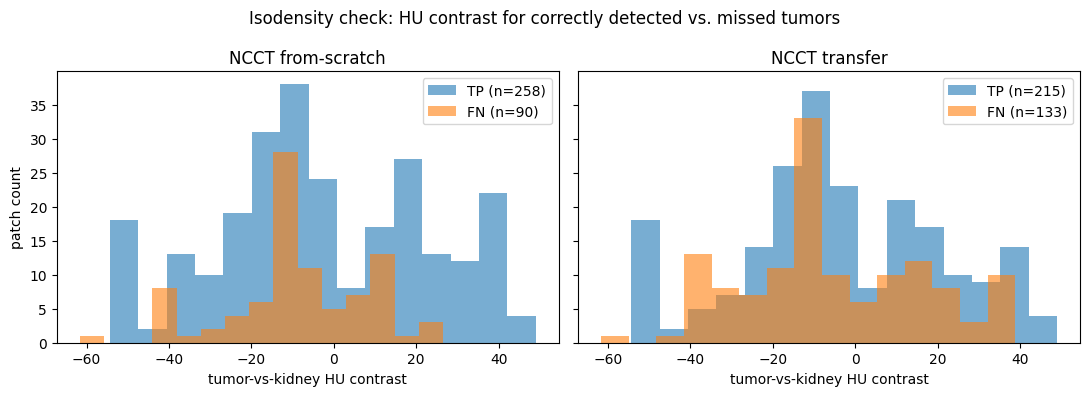

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, df) in zip(axes, [("NCCT from-scratch", scratch_diag), ("NCCT transfer", transfer_diag)]):
    tp_contrast = df[df["outcome"] == "TP"]["contrast_hu"].dropna()
    fn_contrast = df[df["outcome"] == "FN"]["contrast_hu"].dropna()
    ax.hist(tp_contrast, bins=15, alpha=0.6, label=f"TP (n={len(tp_contrast)})")
    ax.hist(fn_contrast, bins=15, alpha=0.6, label=f"FN (n={len(fn_contrast)})")
    ax.set_title(name)
    ax.set_xlabel("tumor-vs-kidney HU contrast")
    ax.legend()
axes[0].set_ylabel("patch count")
plt.suptitle("Isodensity check: HU contrast for correctly detected vs. missed tumors")
plt.tight_layout()
plt.show()


## 7. Save results

In [ ]:
scratch_diag.to_csv(os.path.join(DATA_DIR, "exp5_failure_analysis_scratch.csv"), index=False)
transfer_diag.to_csv(os.path.join(DATA_DIR, "exp5_failure_analysis_transfer.csv"), index=False)
print("Saved per-patch diagnostic results to Drive.")


Saved per-patch diagnostic results to Drive.
